In [2]:
"""
Build a time-binned orientation-index time course, mirroring the structure
of build_speed_time_course() so time_course_orientation.csv has the same
shape as time_course_speed.csv (one row per video per time bin).

Reads:
  all_augmented_csv/results_with_vertices/*.csv   (per-frame tracking data)
  housing_food_condition.xlsx                     (group assignments)

Writes:
  advanced_analysis_plots/time_course_orientation.csv

Per-frame quantities produced (configurable -- see compute_orientation()):
  - oi_ss, oi_fs        : orientation index toward SS / FS, in [-1, 1]
                          default: cos(radians(abs_angle_to_*))
  - facing_ss, facing_fs: boolean, |angle| <= ANGLE_THRESHOLD_DEG

Per-bin quantities written:
  - mean_OI_SS, mean_OI_FS      : mean of oi_* across frames in the bin
  - frac_facing_SS, frac_facing_FS : fraction of frames with facing_* True
  - n_frames                    : frames in this bin
  - bin_start_s, bin_start_min  : for reference / plotting
"""

import os
import re
import numpy as np
import pandas as pd
from glob import glob

# =============================================================================
# CONFIG
# =============================================================================
MASTER_SHEET_PATH = "housing_food_condition.xlsx"
AUGMENTED_CSV_FOLDER = "all_augmented_csv/results_with_vertices"
OUTPUT_FOLDER = "advanced_analysis_plots"

FPS = 25
TIME_BIN_SECONDS = 60                # 1 bin = 1 minute -> 10 bins per session
ANGLE_THRESHOLD_DEG = 45.0           # for frac_facing_*; matches speed script

GROUP_COL_CANDIDATES = ['Treatment', 'Housing', 'Food']

# ---- Frame-level orientation definition -------------------------------------
# If your augmented CSVs already contain a per-frame orientation-index column,
# set these to its name and the script will use it directly instead of
# computing cos(angle). Otherwise leave as None and the default
# cos(radians(abs_angle_to_*)) is used.
EXISTING_OI_COL_SS = None            # e.g. "orientation_index_SS"
EXISTING_OI_COL_FS = None            # e.g. "orientation_index_FS"

# Which frames contribute to the bin mean?
#   "all"       -> every frame in the video (default)
#   "in_zone"   -> only frames with in_SC (for SS) / in_FC (for FS)
ORIENTATION_FRAME_SCOPE = "all"


# =============================================================================
# Helpers (verbatim from the speed build script)
# =============================================================================
def get_base_name_from_file(csv_path):
    base = os.path.basename(csv_path)
    if base.startswith("aug_"):
        base = base[4:]
    if base.endswith(".csv"):
        base = base[:-4]
    return base


def extract_video_name_from_filename(basename, master_videos):
    matches = [mv for mv in master_videos if basename.startswith(mv)]
    if not matches:
        return None
    return max(matches, key=len)


def load_master_sheet(master_path):
    master = pd.read_excel(master_path, sheet_name=0)
    master = master.dropna(subset=['Video'])

    group_cols_available = []
    for col in GROUP_COL_CANDIDATES:
        if col in master.columns:
            group_cols_available.append(col)
        else:
            print(f"  [INFO] Column '{col}' not found in master sheet; skipping.")

    if not group_cols_available:
        raise ValueError(
            f"Master sheet must contain at least one of {GROUP_COL_CANDIDATES}. "
            f"Found: {list(master.columns)}"
        )

    master = master[['Video'] + group_cols_available].copy()
    master.rename(columns={'Video': 'video'}, inplace=True)
    print(f"  Grouping variables found: {group_cols_available}")
    return master, group_cols_available


# =============================================================================
# Frame-level orientation -- THE ONLY NEW LOGIC vs the speed build script
# =============================================================================
def compute_orientation(df,
                        angle_threshold_deg=ANGLE_THRESHOLD_DEG,
                        existing_oi_col_ss=EXISTING_OI_COL_SS,
                        existing_oi_col_fs=EXISTING_OI_COL_FS,
                        scope=ORIENTATION_FRAME_SCOPE):
    """
    Return a dict of frame-level arrays:
        oi_ss, oi_fs          : orientation index toward SS / FS (float)
        facing_ss, facing_fs  : bool, |angle| <= threshold
        mask_ss, mask_fs      : bool, which frames are eligible for the
                                per-bin mean (depends on scope)

    If EXISTING_OI_COL_* are set AND present in df, those columns are used
    verbatim. Otherwise oi_* is computed as cos(radians(abs_angle_to_*)).
    """
    required_angles = ['abs_angle_to_SS', 'abs_angle_to_FS']
    if not all(c in df.columns for c in required_angles):
        return None

    angle_ss = df['abs_angle_to_SS'].values.astype(float)
    angle_fs = df['abs_angle_to_FS'].values.astype(float)

    # --- Orientation index ---
    if existing_oi_col_ss and existing_oi_col_ss in df.columns:
        oi_ss = df[existing_oi_col_ss].values.astype(float)
    else:
        # Default: cos(angle). 1 = facing, 0 = perpendicular, -1 = facing away.
        # NaN angles propagate to NaN OI, which is excluded by nanmean later.
        oi_ss = np.cos(np.radians(angle_ss))

    if existing_oi_col_fs and existing_oi_col_fs in df.columns:
        oi_fs = df[existing_oi_col_fs].values.astype(float)
    else:
        oi_fs = np.cos(np.radians(angle_fs))

    # --- Facing mask (for frac_facing_*) ---
    facing_ss = (angle_ss <= angle_threshold_deg) & (~np.isnan(angle_ss))
    facing_fs = (angle_fs <= angle_threshold_deg) & (~np.isnan(angle_fs))

    # --- Frame scope ---
    if scope == "all":
        mask_ss = np.ones(len(df), dtype=bool)
        mask_fs = np.ones(len(df), dtype=bool)
    elif scope == "in_zone":
        if 'in_SC' in df.columns:
            mask_ss = df['in_SC'].values.astype(bool)
        else:
            mask_ss = np.ones(len(df), dtype=bool)
        if 'in_FC' in df.columns:
            mask_fs = df['in_FC'].values.astype(bool)
        else:
            mask_fs = np.ones(len(df), dtype=bool)
    else:
        raise ValueError(f"Unknown ORIENTATION_FRAME_SCOPE: {scope!r}")

    # An orientation index can only be computed where the angle was measured
    mask_ss = mask_ss & ~np.isnan(angle_ss)
    mask_fs = mask_fs & ~np.isnan(angle_fs)

    return {
        'oi_ss': oi_ss,
        'oi_fs': oi_fs,
        'facing_ss': facing_ss,
        'facing_fs': facing_fs,
        'mask_ss': mask_ss,
        'mask_fs': mask_fs,
    }


def compute_orientation_time_course(orient, video_name,
                                     fps=FPS, bin_seconds=TIME_BIN_SECONDS):
    """
    Bin the session and compute per-bin:
        mean_OI_SS, mean_OI_FS         -- mean of oi_* across eligible frames
        frac_facing_SS, frac_facing_FS -- fraction of eligible frames facing
        n_frames                       -- frames in this bin

    A bin with zero eligible frames gets NaN for the OI/facing columns, not 0
    (matching the speed script's convention).
    """
    n = len(orient['oi_ss'])
    bin_size_frames = max(1, int(round(bin_seconds * fps)))
    time_bin = (np.arange(n) // bin_size_frames).astype(int)

    rows = []
    for b in np.unique(time_bin):
        idx = (time_bin == b)

        def mean_or_nan(vals, mask):
            sel = mask & idx
            return float(np.nanmean(vals[sel])) if sel.any() else np.nan

        def frac_or_nan(vals, mask):
            sel = mask & idx
            return float(np.mean(vals[sel])) if sel.any() else np.nan

        rows.append({
            'video': video_name,
            'time_bin': int(b),
            'bin_start_s': b * bin_seconds,
            'bin_start_min': b * bin_seconds / 60.0,
            'mean_OI_SS': mean_or_nan(orient['oi_ss'], orient['mask_ss']),
            'mean_OI_FS': mean_or_nan(orient['oi_fs'], orient['mask_fs']),
            'frac_facing_SS': frac_or_nan(orient['facing_ss'], orient['mask_ss']),
            'frac_facing_FS': frac_or_nan(orient['facing_fs'], orient['mask_fs']),
            'n_frames': int(idx.sum()),
        })
    return pd.DataFrame(rows)


# =============================================================================
# Main
# =============================================================================
def build_orientation_time_course(aug_folder=AUGMENTED_CSV_FOLDER,
                                   master_path=MASTER_SHEET_PATH,
                                   output_folder=OUTPUT_FOLDER,
                                   fps=FPS,
                                   bin_seconds=TIME_BIN_SECONDS,
                                   angle_threshold_deg=ANGLE_THRESHOLD_DEG):
    os.makedirs(output_folder, exist_ok=True)

    master, GROUP_COLS = load_master_sheet(master_path)
    master_videos = set(master['video'])

    all_csv = glob(os.path.join(aug_folder, '*.csv'))
    valid_csv = []
    for f in all_csv:
        try:
            df_sample = pd.read_csv(f, nrows=5)
            if ('abs_angle_to_SS' in df_sample.columns
                    and 'abs_angle_to_FS' in df_sample.columns):
                valid_csv.append(f)
        except Exception:
            continue

    video_files = {}
    for f in valid_csv:
        basename = get_base_name_from_file(f)
        video_name = extract_video_name_from_filename(basename, master_videos)
        if video_name is None:
            match = re.search(r'(MVI_\d+_roi\d+)', basename)
            video_name = match.group(1) if match else None
        if video_name is None:
            print(f"  [WARN] Could not extract video name from {basename}. Skipping.")
            continue
        if video_name in video_files:
            print(f"  [WARN] Duplicate video '{video_name}': {f} and "
                  f"{video_files[video_name]}. Skipping {f}.")
            continue
        video_files[video_name] = f

    if not video_files:
        print(f"No valid video files found in {aug_folder}")
        return None

    print(f"Found {len(video_files)} unique videos. "
          f"Facing angle threshold = {angle_threshold_deg}°, "
          f"bin = {bin_seconds} s.")

    time_course_rows = []
    for vname, csv_path in video_files.items():
        print(f"Processing {vname} ...")
        df = pd.read_csv(csv_path)

        orient = compute_orientation(df,
                                     angle_threshold_deg=angle_threshold_deg)
        if orient is None:
            print(f"  [SKIP] Missing required angle columns in {csv_path}.")
            continue

        if vname in master_videos:
            row_match = master.loc[master['video'] == vname].iloc[0]
            group_values = {
                gc: (row_match[gc] if pd.notna(row_match[gc]) else 'unknown')
                for gc in GROUP_COLS
            }
        else:
            print(f"  [WARN] {vname} not in master sheet; "
                  f"grouping variables set to 'unknown'.")
            group_values = {gc: 'unknown' for gc in GROUP_COLS}

        tc = compute_orientation_time_course(orient, vname,
                                              fps=fps, bin_seconds=bin_seconds)
        for gc in GROUP_COLS:
            tc[gc] = group_values[gc]
        time_course_rows.append(tc)

    if not time_course_rows:
        print("No videos produced usable data.")
        return None

    time_course_df = pd.concat(time_course_rows, ignore_index=True)
    out_path = os.path.join(output_folder, 'time_course_orientation.csv')
    time_course_df.to_csv(out_path, index=False)
    print(f"\n✅ Orientation time-course saved to {out_path}")

    # Quick sanity print so you can eyeball the ranges immediately
    print("\nColumn ranges (per-bin means across all videos):")
    for col in ['mean_OI_SS', 'mean_OI_FS', 'frac_facing_SS', 'frac_facing_FS']:
        s = time_course_df[col].dropna()
        if len(s):
            print(f"  {col:18s}  min={s.min():+.3f}  "
                  f"median={s.median():+.3f}  max={s.max():+.3f}  "
                  f"n={len(s)}")
        else:
            print(f"  {col:18s}  ALL NaN -- check your angle columns!")

    print(f"\nVideos: {time_course_df['video'].nunique()}, "
          f"bins per video (median): "
          f"{time_course_df.groupby('video').size().median():.0f}")
    print("Treatment counts (unique videos):")
    print(time_course_df.groupby('Treatment')['video'].nunique())

    return time_course_df


if __name__ == "__main__":
    build_orientation_time_course()

  Grouping variables found: ['Treatment', 'Housing', 'Food']
Found 49 unique videos. Facing angle threshold = 45.0°, bin = 60 s.
Processing MVI_0614_roi2 ...
Processing MVI_0091_roi1 ...
Processing MVI_0616_roi1 ...
Processing MVI_0075_roi1 ...
Processing MVI_0319_roi2 ...
Processing MVI_0083_roi1 ...
Processing MVI_0081_roi2 ...
Processing MVI_0311_roi1 ...
Processing MVI_0322_roi1 ...
Processing MVI_0006_roi2 ...
Processing MVI_0074_roi1 ...
Processing MVI_0617_roi1 ...
Processing MVI_0611_roi1 ...
Processing MVI_0618_roi2 ...
Processing MVI_0010_roi1 ...
Processing MVI_0086_roi2 ...
Processing MVI_0327_roi2 ...
Processing MVI_0011_roi1 ...
Processing MVI_0325_roi1 ...
Processing MVI_0314_roi2 ...
Processing MVI_0013_roi2 ...
Processing MVI_0612_roi2 ...
Processing MVI_0008_roi1 ...
Processing MVI_0078_roi1 ...
Processing MVI_0010_roi2 ...
Processing MVI_0086_roi1 ...
Processing MVI_0611_roi2 ...
Processing MVI_0010_roi2copy ...
Processing MVI_0618_roi1 ...
Processing MVI_0612_roi1 .

In [3]:
"""
Time-course orientation analysis for the housing/food experiment.

Input : time_course_orientation.csv  (already 60 s-binned, 10 bins per video)
Master: housing_food_condition.xlsx  (one row per video; Treatment/Housing/Food)

Stages
------
3. Per-video linear fits of each orientation outcome on time_bin
   -> time_course_orientation_fit_quality.csv
4. Treatment x time trends:
      GEE  outcome ~ time_bin * C(Treatment), groups=video,
           Gaussian identity, AR(1) primary + exchangeable + independence
           robust (sandwich) SEs, small-sample t correction
      MixedLM  outcome ~ time_bin * C(Treatment), groups=video,
           re_formula = ~time_bin, reml=False
   -> time_course_orientation_treatment_trends.csv
"""

from __future__ import annotations

import re
import warnings
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
from scipy import stats

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.genmod.cov_struct import Autoregressive, Exchangeable, Independence
from statsmodels.genmod.families import Gaussian
from statsmodels.genmod.generalized_estimating_equations import GEE
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


# --------------------------------------------------------------------------
# Configuration
# --------------------------------------------------------------------------
BINNED_CSV = "advanced_analysis_plots/time_course_orientation.csv"
MASTER_XLSX = "housing_food_condition.xlsx"

OUT_FITS = "time_course_orientation_fit_quality.csv"
OUT_TRENDS = "time_course_orientation_treatment_trends.csv"

# Outcomes to model. Each must be a per-bin numeric column in the CSV.
PRIMARY_OUTCOMES = ["mean_OI_SS", "mean_OI_FS"]
SECONDARY_OUTCOMES = ["frac_facing_SS", "frac_facing_FS"]
OUTCOMES = PRIMARY_OUTCOMES + SECONDARY_OUTCOMES

REFERENCE_GROUP = "GH AL"
TREATMENT_LEVELS = ["GH AL", "GH FD", "SH AL", "SH FD"]

MIN_BINS_FOR_FIT = 3   # skip videos with fewer usable bins


# --------------------------------------------------------------------------
# Loading & joining
# --------------------------------------------------------------------------
def load_master() -> pd.DataFrame:
    df = pd.read_excel(MASTER_XLSX, sheet_name="PI Analysis")
    df = df.rename(columns={
        "Video": "video",
        "Animal ID": "animal_id",   # optional, kept for reference
        "Treatment": "Treatment",
        "Housing": "Housing",
        "Food": "Food",
    })
    # normalise video IDs so they match the binned CSV
    df["video"] = (df["video"].astype(str)
                   .str.strip()
                   .str.replace(r"\.csv$", "", regex=True))
    df["Treatment"] = df["Treatment"].astype(str).str.strip()
    df["Housing"]   = df["Housing"].astype(str).str.strip()
    df["Food"]      = df["Food"].astype(str).str.strip()

    keep = ["video", "Treatment", "Housing", "Food"]
    df = df[keep].drop_duplicates(subset="video")
    print(f"[load_master] {len(df)} unique videos; "
          f"Treatment levels: {sorted(df['Treatment'].unique())}")
    return df


def load_binned() -> pd.DataFrame:
    df = pd.read_csv(BINNED_CSV)
    # sanity: normalize video id
    df["video"] = df["video"].astype(str).str.strip()
    return df


def attach_grouping(binned: pd.DataFrame, master: pd.DataFrame) -> pd.DataFrame:
    df = binned.merge(master, on="video", how="left", validate="many_to_one")
    missing = df["Treatment"].isna()
    if missing.any():
        bad = sorted(df.loc[missing, "video"].unique())
        raise ValueError(
            "These videos in the binned CSV are not in the master sheet: "
            f"{bad}. Check spelling/casing of video IDs."
        )
    return df


# --------------------------------------------------------------------------
# Reference-level handling
# --------------------------------------------------------------------------
def ensure_reference(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["Treatment"] = df["Treatment"].astype(str).str.strip()
    present = set(df["Treatment"].unique())
    if REFERENCE_GROUP not in present:
        raise ValueError(
            f"Reference group {REFERENCE_GROUP!r} not found in Treatment. "
            f"Present levels: {sorted(present)}. Check spelling/casing."
        )
    extra = present - set(TREATMENT_LEVELS)
    if extra:
        raise ValueError(f"Unexpected Treatment levels: {sorted(extra)}")
    order = [REFERENCE_GROUP] + [l for l in TREATMENT_LEVELS
                                 if l != REFERENCE_GROUP]
    df["Treatment"] = pd.Categorical(df["Treatment"],
                                     categories=order, ordered=True)
    return df


# --------------------------------------------------------------------------
# Stage 3 — per-video fit quality
# --------------------------------------------------------------------------
def per_video_fits(binned: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for video, g in binned.groupby("video", sort=False):
        g = g.sort_values("time_bin")
        for outcome in OUTCOMES:
            if outcome not in g.columns:
                continue
            sub = g[["time_bin", outcome]].dropna()
            n = len(sub)
            if n < MIN_BINS_FOR_FIT:
                continue
            x = sub["time_bin"].to_numpy(float)
            y = sub[outcome].to_numpy(float)
            # guard against zero variance in y (constant bins)
            if np.ptp(y) == 0:
                rows.append({
                    "video": video, "outcome": outcome,
                    "slope": 0.0, "intercept": float(y[0]),
                    "r_squared": np.nan, "p_value": np.nan,
                    "std_err": np.nan, "n_bins": n,
                })
                continue
            lr = stats.linregress(x, y)
            rows.append({
                "video": video, "outcome": outcome,
                "slope": lr.slope, "intercept": lr.intercept,
                "r_squared": lr.rvalue ** 2,
                "p_value": lr.pvalue, "std_err": lr.stderr,
                "n_bins": n,
            })
    return pd.DataFrame(rows)


# --------------------------------------------------------------------------
# Stage 4 — GEE / MixedLM
# --------------------------------------------------------------------------
def _fit_gee(df: pd.DataFrame, outcome: str, cov_struct) -> GEE:
    formula = f"{outcome} ~ time_bin * C(Treatment)"
    model = GEE.from_formula(
        formula, groups=df["video"], data=df,
        family=Gaussian(), cov_struct=cov_struct,
    )
    return model.fit(cov_type="robust")


def _wald_interaction(res) -> Tuple[float, int, float]:
    names = list(res.params.index)
    inter = [n for n in names
             if re.match(r"time_bin:C\(Treatment\)", n)]
    if not inter:
        return np.nan, 0, np.nan
    R = np.zeros((len(inter), len(names)))
    for i, n in enumerate(inter):
        R[i, names.index(n)] = 1.0
    w = res.wald_test(R, scalar=True)
    return float(w.statistic), int(w.df_denom), float(w.pvalue)


def _extract_gee_terms(res, model_name: str, outcome: str, ref: str,
                       n_clusters: int, n_obs: int,
                       global_stat: float, global_df: int, global_p: float
                       ) -> List[dict]:
    rows = []
    params = res.params
    bse = res.bse
    cov = res.cov_params()
    # small-sample t correction: df = n_clusters - n_params
    df_t = max(n_clusters - len(params), 1)
    tcrit = stats.t.ppf(0.975, df_t)

    # interaction terms
    for name in params.index:
        m = re.match(r"time_bin:C\(Treatment\)\[T\.(.+)\]", name)
        if not m:
            continue
        group = m.group(1)
        beta, se = float(params[name]), float(bse[name])
        tstat = beta / se if se > 0 else np.nan
        rows.append({
            "outcome": outcome, "model": model_name,
            "term_type": "interaction", "term": group,
            "beta": beta, "se": se,
            "ci_low": beta - tcrit * se, "ci_high": beta + tcrit * se,
            "stat_name": "t", "stat_value": tstat,
            "p_value": 2 * stats.t.sf(abs(tstat), df_t) if np.isfinite(tstat) else np.nan,
            "p_value_holm": np.nan,
            "n_clusters": n_clusters, "n_obs": n_obs,
            "global_wald_stat": global_stat, "global_wald_df": global_df,
            "global_wald_p": global_p,
            "reference_group": ref,
        })

    # simple slopes from the single 4-level model
    base = float(params["time_bin"])
    base_se = float(bse["time_bin"])
    base_t = base / base_se if base_se > 0 else np.nan
    rows.append({
        "outcome": outcome, "model": model_name,
        "term_type": "simple_slope", "term": ref,
        "beta": base, "se": base_se,
        "ci_low": base - tcrit * base_se, "ci_high": base + tcrit * base_se,
        "stat_name": "t", "stat_value": base_t,
        "p_value": 2 * stats.t.sf(abs(base_t), df_t) if np.isfinite(base_t) else np.nan,
        "p_value_holm": np.nan,
        "n_clusters": n_clusters, "n_obs": n_obs,
        "global_wald_stat": global_stat, "global_wald_df": global_df,
        "global_wald_p": global_p,
        "reference_group": ref,
    })
    for name in params.index:
        m = re.match(r"time_bin:C\(Treatment\)\[T\.(.+)\]", name)
        if not m:
            continue
        group = m.group(1)
        slope = base + float(params[name])
        v = cov.loc[["time_bin", name], ["time_bin", name]].values
        se = float(np.sqrt(v[0, 0] + v[1, 1] + 2 * v[0, 1]))
        tstat = slope / se if se > 0 else np.nan
        rows.append({
            "outcome": outcome, "model": model_name,
            "term_type": "simple_slope", "term": group,
            "beta": slope, "se": se,
            "ci_low": slope - tcrit * se, "ci_high": slope + tcrit * se,
            "stat_name": "t", "stat_value": tstat,
            "p_value": 2 * stats.t.sf(abs(tstat), df_t) if np.isfinite(tstat) else np.nan,
            "p_value_holm": np.nan,
            "n_clusters": n_clusters, "n_obs": n_obs,
            "global_wald_stat": global_stat, "global_wald_df": global_df,
            "global_wald_p": global_p,
            "reference_group": ref,
        })
    return rows


def _fit_mixedlm(df: pd.DataFrame, outcome: str):
    formula = f"{outcome} ~ time_bin * C(Treatment)"
    md = smf.mixedlm(formula, data=df, groups=df["video"],
                     re_formula="~time_bin")
    return md.fit(reml=False, method="lbfgs", maxiter=500)


def _extract_mixedlm_terms(res, outcome: str, ref: str,
                           n_clusters: int, n_obs: int) -> List[dict]:
    rows = []
    params = res.params
    bse = res.bse
    pvals = res.pvalues
    try:
        cov = res.cov_params()
    except Exception:
        cov = None
    tcrit = stats.t.ppf(0.975, max(n_clusters - 1, 1))

    # interaction terms
    for name in params.index:
        m = re.match(r"time_bin:C\(Treatment\)\[T\.(.+)\]", name)
        if not m:
            continue
        group = m.group(1)
        beta, se = float(params[name]), float(bse[name])
        rows.append({
            "outcome": outcome, "model": "MixedLM",
            "term_type": "interaction", "term": group,
            "beta": beta, "se": se,
            "ci_low": beta - tcrit * se, "ci_high": beta + tcrit * se,
            "stat_name": "z", "stat_value": float(res.tvalues[name]),
            "p_value": float(pvals[name]), "p_value_holm": np.nan,
            "n_clusters": n_clusters, "n_obs": n_obs,
            "global_wald_stat": np.nan, "global_wald_df": np.nan,
            "global_wald_p": np.nan,
            "reference_group": ref,
        })

    # simple slopes from the single model
    base = float(params["time_bin"])
    base_se = float(bse["time_bin"])
    rows.append({
        "outcome": outcome, "model": "MixedLM",
        "term_type": "simple_slope", "term": ref,
        "beta": base, "se": base_se,
        "ci_low": base - tcrit * base_se, "ci_high": base + tcrit * base_se,
        "stat_name": "z", "stat_value": float(res.tvalues["time_bin"]),
        "p_value": float(pvals["time_bin"]), "p_value_holm": np.nan,
        "n_clusters": n_clusters, "n_obs": n_obs,
        "global_wald_stat": np.nan, "global_wald_df": np.nan,
        "global_wald_p": np.nan,
        "reference_group": ref,
    })
    for name in params.index:
        m = re.match(r"time_bin:C\(Treatment\)\[T\.(.+)\]", name)
        if not m:
            continue
        group = m.group(1)
        slope = base + float(params[name])
        if cov is not None:
            try:
                v = cov.loc[["time_bin", name], ["time_bin", name]].values
                se = float(np.sqrt(v[0, 0] + v[1, 1] + 2 * v[0, 1]))
            except Exception:
                se = float(np.hypot(base_se, bse[name]))
        else:
            se = float(np.hypot(base_se, bse[name]))
        rows.append({
            "outcome": outcome, "model": "MixedLM",
            "term_type": "simple_slope", "term": group,
            "beta": slope, "se": se,
            "ci_low": slope - tcrit * se, "ci_high": slope + tcrit * se,
            "stat_name": "z",
            "stat_value": slope / se if se > 0 else np.nan,
            "p_value": np.nan, "p_value_holm": np.nan,
            "n_clusters": n_clusters, "n_obs": n_obs,
            "global_wald_stat": np.nan, "global_wald_df": np.nan,
            "global_wald_p": np.nan,
            "reference_group": ref,
        })
    return rows


def treatment_trends(binned: pd.DataFrame) -> pd.DataFrame:
    df = ensure_reference(binned)
    df = df.dropna(subset=["Treatment"])
    rows = []

    for outcome in OUTCOMES:
        if outcome not in df.columns:
            print(f"[skip] outcome {outcome!r} not in binned CSV")
            continue
        sub = df.dropna(subset=[outcome]).copy()
        # keep only videos that actually contribute
        sub = sub[sub["Treatment"].isin(TREATMENT_LEVELS)]
        if sub["Treatment"].nunique() < 2:
            print(f"[skip] {outcome}: fewer than 2 treatment groups with data")
            continue

        n_clusters = sub["video"].nunique()
        n_obs = len(sub)
        print(f"\n=== {outcome} | n_clusters={n_clusters} | n_obs={n_obs} ===")

        # --- GEE AR(1) primary ---
        for model_name, cs in [
            ("GEE_AR1", Autoregressive()),
            ("GEE_Exchangeable", Exchangeable()),
            ("GEE_Independence", Independence()),
        ]:
            try:
                r = _fit_gee(sub, outcome, cs)
                gstat, gdf, gp = _wald_interaction(r)
                rows += _extract_gee_terms(r, model_name, outcome,
                                           REFERENCE_GROUP,
                                           n_clusters, n_obs,
                                           gstat, gdf, gp)
                print(f"  {model_name}: global Wald χ²={gstat:.3f} "
                      f"df={gdf} p={gp:.4g}")
            except Exception as e:
                print(f"  [{model_name} failed for {outcome}: {e}]")

        # --- MixedLM sensitivity ---
        try:
            mlm = _fit_mixedlm(sub, outcome)
            rows += _extract_mixedlm_terms(mlm, outcome, REFERENCE_GROUP,
                                           n_clusters, n_obs)
            print(f"  MixedLM: converged={mlm.converged}")
        except Exception as e:
            print(f"  [MixedLM failed for {outcome}: {e}]")

    out = pd.DataFrame(rows)
    if out.empty:
        return out

    # Holm correction across the 3 interaction contrasts within each
    # (outcome, model) block
    def _holm(g):
        g = g.copy()
        p = g["p_value"].to_numpy()
        mask = np.isfinite(p)
        if mask.sum() == 0:
            return g
        _, adj, _, _ = multipletests(p[mask], method="holm")
        g.loc[g.index[mask], "p_value_holm"] = adj
        return g

    out = out.groupby(["outcome", "model"], group_keys=False).apply(_holm)
    return out.reset_index(drop=True)


# --------------------------------------------------------------------------
# Cross-check: model-derived simple slopes vs raw per-bin group means
# --------------------------------------------------------------------------
def crosscheck_simple_slopes(binned: pd.DataFrame, trends: pd.DataFrame):
    print("\n--- Simple-slope cross-check (raw group means) ---")
    for outcome in OUTCOMES:
        if outcome not in binned.columns:
            continue
        sub = binned.dropna(subset=[outcome, "Treatment"])
        sub = sub[sub["Treatment"].isin(TREATMENT_LEVELS)]
        if sub.empty:
            continue
        means = (sub.groupby(["Treatment", "time_bin"], observed=True)[outcome]
                 .mean().reset_index())
        print(f"\n{outcome}")
        for trt, g in means.groupby("Treatment", observed=True):
            if len(g) < 3:
                continue
            lr = stats.linregress(g["time_bin"], g[outcome])
            # model-derived value, if present
            mdl = trends[
                (trends["outcome"] == outcome)
                & (trends["model"] == "GEE_AR1")
                & (trends["term_type"] == "simple_slope")
                & (trends["term"] == trt)
            ]
            mdl_beta = mdl["beta"].iloc[0] if len(mdl) else np.nan
            flag = ""
            if np.isfinite(mdl_beta) and np.sign(mdl_beta) != np.sign(lr.slope):
                flag = "  <-- SIGN MISMATCH"
            print(f"  {trt:6s} raw slope = {lr.slope:+.4f} "
                  f"(R²={lr.rvalue**2:.3f}, n={len(g)}) | "
                  f"GEE_AR1 simple slope = {mdl_beta:+.4f}{flag}")


# --------------------------------------------------------------------------
# Main
# --------------------------------------------------------------------------
def main():
    binned = load_binned()          # already has Treatment/Housing/Food

    # sanity: confirm grouping columns are present and clean
    for col in ("Treatment", "Housing", "Food"):
        if col not in binned.columns:
            raise ValueError(f"Binned CSV is missing {col!r}. "
                             f"Columns: {list(binned.columns)}")
        binned[col] = binned[col].astype(str).str.strip()

    print(f"Loaded {binned['video'].nunique()} videos, "
          f"{len(binned)} bin rows.")
    print("Treatment counts (unique videos):")
    print(binned.groupby("Treatment")["video"].nunique())

    # Stage 3
    fits = per_video_fits(binned)
    fits.to_csv(OUT_FITS, index=False)
    print(f"\nWrote {OUT_FITS} ({len(fits)} rows)")
    if not fits.empty:
        print("\n--- Per-video fit quality summary ---")
        for outcome, g in fits.groupby("outcome", sort=False):
            r2 = g["r_squared"].dropna()
            print(f"  {outcome:18s} n={len(g):2d}  "
                  f"R² med/mean/range = "
                  f"{r2.median():.3f} / {r2.mean():.3f} / "
                  f"[{r2.min():.3f}, {r2.max():.3f}]  "
                  f"p<0.05: {(g['p_value'] < 0.05).sum()}  "
                  f"median slope = {g['slope'].median():+.4f}")

    # Stage 4
    trends = treatment_trends(binned)
    trends.to_csv(OUT_TRENDS, index=False)
    print(f"\nWrote {OUT_TRENDS} ({len(trends)} rows)")

    crosscheck_simple_slopes(binned, trends)


if __name__ == "__main__":
    main()

Loaded 49 videos, 490 bin rows.
Treatment counts (unique videos):
Treatment
GH AL    10
GH FD    10
SH AL    11
SH FD    18
Name: video, dtype: int64

Wrote time_course_orientation_fit_quality.csv (196 rows)

--- Per-video fit quality summary ---
  mean_OI_SS         n=49  R² med/mean/range = 0.256 / 0.285 / [0.000, 0.933]  p<0.05: 9  median slope = -0.0398
  mean_OI_FS         n=49  R² med/mean/range = 0.201 / 0.278 / [0.001, 0.871]  p<0.05: 14  median slope = -0.0480
  frac_facing_SS     n=49  R² med/mean/range = 0.250 / 0.274 / [0.000, 0.746]  p<0.05: 9  median slope = -0.0231
  frac_facing_FS     n=49  R² med/mean/range = 0.179 / 0.266 / [0.006, 0.839]  p<0.05: 15  median slope = -0.0310

=== mean_OI_SS | n_clusters=49 | n_obs=449 ===
  GEE_AR1: global Wald χ²=2.210 df=3 p=0.53
  GEE_Exchangeable: global Wald χ²=3.083 df=3 p=0.3791
  GEE_Independence: global Wald χ²=2.889 df=3 p=0.409
  MixedLM: converged=True

=== mean_OI_FS | n_clusters=49 | n_obs=453 ===
  GEE_AR1: global Wald χ

/var/folders/94/3s7t4knx581_57x7rxmjxqh00000gn/T/ipykernel_22454/1338441516.py:414: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = out.groupby(["outcome", "model"], group_keys=False).apply(_holm)


In [4]:
"""
Plotting for the treatment x time ORIENTATION-index trend analysis.

Reads:
  advanced_analysis_plots/time_course_orientation.csv
  advanced_analysis_plots/time_course_orientation_treatment_trends.csv

Writes (PNG + PDF for each):
  1. fig1_timecourse_ribbons_orientation.png
  2. fig2_spaghetti_by_group_orientation.png
  3. fig3_slope_forest_orientation.png
  4. fig4_interaction_forest_orientation.png

Design choices (identical in structure to the speed version):
- Two outcomes (SS = social, FS = food) shown side by side.
- Reference group (GH AL) drawn in a heavier line.
- Colours match the published figure.
- Y-axis on both outcome panels is shared and truncated (OI is ~[-1, 1];
  we clip to [-1, 1] and let the clipping warnings fire if data exceed it).
- X-axis runs 0 -> 10 minutes; ticks hyphenated (0-1, 1-2, ... 9-10).
- Font is Arial, size 12, bold.
- Slope figures use OI units per MINUTE (per-bin == per-minute since
  the bin is 60 s).
- Forest plots show both GEE (robust) and MixedLM CIs on the same row.
"""

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats

# =============================================================================
# CONFIG
# =============================================================================
OUTPUT_FOLDER = ""
TIME_COURSE_CSV = "time_course_orientation.csv"
TRENDS_CSV = "time_course_orientation_treatment_trends.csv"
TREATMENT_COL = "Treatment"
REFERENCE_GROUP = "GH AL"

# Primary outcomes are the orientation-index means. If you'd rather plot the
# secondary facing-fraction outcomes instead, swap these two lists.
OUTCOMES = ["mean_OI_SS", "mean_OI_FS"]
OUTCOME_LABELS = {
    "mean_OI_SS": "Orientation index toward social stimulus (SS)",
    "mean_OI_FS": "Orientation index toward food stimulus (FS)",
}
# For the secondary outcome, uncomment this block and the corresponding
# OUTCOMES list above:
# OUTCOMES = ["frac_facing_SS", "frac_facing_FS"]
# OUTCOME_LABELS = {
#     "frac_facing_SS": "Fraction of frames facing social stimulus (SS)",
#     "frac_facing_FS": "Fraction of frames facing food stimulus (FS)",
# }

BIN_SECONDS = 60          # 1 bin = 1 minute
X_MAX_MINUTES = 10        # x-axis runs 0 -> 10 min

# --- Y-axis limits -----------------------------------------------------------
# Orientation index is bounded. The exact bounds depend on how it's defined;
# change these to match. If OI is in [-1, 1]:
Y_MIN_OI = -1.0
Y_MAX_OI = 1.0
# If OI is in [0, 1] (e.g. cos(angle) after clipping, or a proportion):
# Y_MIN_OI = 0.0
# Y_MAX_OI = 1.0

# --- Font: Arial, size 12, bold ---
FONT_FAMILY = "Arial"
FONT_SIZE = 12
FONT_WEIGHT = "bold"

# -----------------------------------------------------------------------------
# Colour scheme: MATCHES THE PUBLISHED FIGURE.
# -----------------------------------------------------------------------------
GROUP_COLORS = {
    "GH AL": "#D55E00",   # dark orange-red   (reference group)
    "GH FD": "#E69F00",   # light orange
    "SH AL": "#155D86",   # dark blue
    "SH FD": "#39CECE",   # light aqua
}
DEFAULT_COLOR = "#7F7F7F"

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,

    "font.family": "sans-serif",
    "font.sans-serif": [FONT_FAMILY, "Helvetica", "DejaVu Sans"],
    "font.size": FONT_SIZE,
    "font.weight": FONT_WEIGHT,
    "axes.titlesize": FONT_SIZE,
    "axes.titleweight": FONT_WEIGHT,
    "axes.labelsize": FONT_SIZE,
    "axes.labelweight": FONT_WEIGHT,
    "legend.fontsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "figure.titlesize": FONT_SIZE,
    "figure.titleweight": FONT_WEIGHT,
    "text.color": "black",
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",

    "axes.spines.top": False,
    "axes.spines.right": False,
})


# =============================================================================
# Helpers
# =============================================================================
def _color_for(group):
    return GROUP_COLORS.get(group, DEFAULT_COLOR)


def _save(fig, name):
    for ext in ("png", "pdf"):
        path = os.path.join(OUTPUT_FOLDER, f"{name}.{ext}")
        fig.savefig(path, bbox_inches="tight")
    print(f"  saved {name}.png / .pdf")


def _order_groups(groups):
    """Reference group first, then alphabetical."""
    groups = sorted(groups)
    if REFERENCE_GROUP in groups:
        groups = [REFERENCE_GROUP] + [g for g in groups if g != REFERENCE_GROUP]
    return groups


def _hyphenated_minute_ticks(ax, tmax_minutes=10, step=1):
    """
    Label x ticks as '0-1', '1-2', ... '9-10' so the reader sees each tick
    is the centre of a 1-minute bin.
    """
    dash = "\u2013"
    ticks = np.arange(0, tmax_minutes, step)
    labels = [f"{int(t)}{dash}{int(t + step)}" for t in ticks]

    ax.set_xticks(ticks)
    ax.set_xticklabels(labels)
    ax.set_xlim(-0.2, tmax_minutes + 0.2)

    ax.set_xticks(np.arange(0.5, tmax_minutes, step), minor=True)
    ax.tick_params(axis="x", which="minor", length=3, color="0.5")

    for lbl in ax.get_xticklabels():
        lbl.set_clip_on(False)


# =============================================================================
# FIGURE 1 -- model-fitted per-group time course with model-based CI
# =============================================================================
def _fit_group_curve(df, outcome, treatment_col, family=None,
                     working_corr="ar"):
    """
    Fit the same GEE as the analysis stage and return, per group, the fitted
    marginal mean at every time bin plus a 95% CI ribbon.

    Identical to the speed version; only the outcome column name changes.
    """
    import statsmodels.api as sm
    import statsmodels.formula.api as smf

    if family is None:
        family = sm.families.Gaussian()

    cov_map = {
        "ar": sm.cov_struct.Autoregressive,
        "exchangeable": sm.cov_struct.Exchangeable,
        "independence": sm.cov_struct.Independence,
    }

    sub = df[["video", "time_bin", treatment_col, outcome]].dropna(subset=[outcome]).copy()
    sub[treatment_col] = sub[treatment_col].astype("category")

    formula = f"{outcome} ~ time_bin * C({treatment_col})"
    model = smf.gee(
        formula=formula,
        groups="video",
        data=sub,
        family=family,
        cov_struct=cov_map[working_corr](),
    )
    res = model.fit(cov_type="robust")

    bins = np.sort(sub["time_bin"].unique())
    groups = sorted(sub[treatment_col].cat.categories.tolist())

    pred_rows = []
    for grp in groups:
        for b in bins:
            pred_rows.append({"time_bin": b, treatment_col: grp})
    pred_df = pd.DataFrame(pred_rows)
    pred_df[treatment_col] = pd.Categorical(
        pred_df[treatment_col], categories=sub[treatment_col].cat.categories
    )

    pred = res.predict(pred_df)

    from patsy import dmatrix
    design_info = res.model.data.design_info
    X = dmatrix(design_info, pred_df, return_type="dataframe")
    X = X[res.params.index]
    Xv = X.values
    vcov = res.cov_params().values
    se = np.sqrt(np.einsum("ij,jk,ik->i", Xv, vcov, Xv))
    ci_low = pred - 1.96 * se
    ci_high = pred + 1.96 * se

    out = pd.DataFrame({
        "group": pred_df[treatment_col].astype(str).values,
        "time_bin": pred_df["time_bin"].values,
        "fitted": pred.values,
        "ci_low": ci_low,
        "ci_high": ci_high,
    })
    return out


def plot_timecourse_ribbons(df):
    """
    Model-fitted per-group trajectories with model-based 95% CI ribbons.
    Raw bin means drawn as faint dots. Y-axis shared across SS/FS panels.
    """
    groups = _order_groups(df[TREATMENT_COL].dropna().unique().tolist())

    fig, axes = plt.subplots(
        1, 2, figsize=(11, 4.2), sharey=True
    )
    for ax, outcome in zip(axes, OUTCOMES):
        fitted = _fit_group_curve(df, outcome, TREATMENT_COL)

        for grp in groups:
            fg = fitted[fitted["group"] == grp].sort_values("time_bin")
            if fg.empty:
                continue
            x = fg["time_bin"] * (BIN_SECONDS / 60.0)
            color = _color_for(grp)
            lw = 2.4 if grp == REFERENCE_GROUP else 1.8

            ax.plot(x, fg["fitted"], color=color, lw=lw, label=grp, zorder=3)
            ax.fill_between(x, fg["ci_low"], fg["ci_high"],
                            color=color, alpha=0.18, lw=0, zorder=2)

            raw = (df[df[TREATMENT_COL] == grp]
                   .groupby("time_bin")[outcome].mean().reset_index())
            xr = raw["time_bin"] * (BIN_SECONDS / 60.0)
            ax.scatter(xr, raw[outcome], color=color, s=14, alpha=0.55,
                       edgecolor="white", linewidth=0.5, zorder=4)

        ax.set_xlabel("Time in session (minutes)")
        ax.set_title(OUTCOME_LABELS[outcome])
        ax.set_ylim(Y_MIN_OI, Y_MAX_OI)
        ax.tick_params(axis="y", labelleft=True)
        _hyphenated_minute_ticks(ax, X_MAX_MINUTES)

        # Clipping warnings
        if pd.notna(fitted["ci_low"].min()) and fitted["ci_low"].min() < Y_MIN_OI:
            print(f"  [WARN] {outcome}: fitted CI lower bound "
                  f"{fitted['ci_low'].min():.2f} < Y_MIN_OI = {Y_MIN_OI}; "
                  f"ribbon will be clipped at the bottom.")
        if pd.notna(fitted["ci_high"].max()) and fitted["ci_high"].max() > Y_MAX_OI:
            print(f"  [WARN] {outcome}: fitted CI upper bound "
                  f"{fitted['ci_high'].max():.2f} > Y_MAX_OI = {Y_MAX_OI}; "
                  f"ribbon will be clipped at the top.")
        if pd.notna(df[outcome].min()) and df[outcome].min() < Y_MIN_OI:
            print(f"  [WARN] {outcome}: raw min {df[outcome].min():.2f} "
                  f"< Y_MIN_OI = {Y_MIN_OI}; some points will be clipped.")
        if pd.notna(df[outcome].max()) and df[outcome].max() > Y_MAX_OI:
            print(f"  [WARN] {outcome}: raw max {df[outcome].max():.2f} "
                  f"> Y_MAX_OI = {Y_MAX_OI}; some points will be clipped.")

    axes[0].set_ylabel("Orientation index")
    axes[1].set_ylabel("")
    axes[0].legend(frameon=False, loc="best")

    fig.suptitle("Model-fitted orientation index over the session, by treatment group "
                 "(GEE fit; ribbon = 95% CI; dots = raw bin means)",
                 y=1.03, fontsize=FONT_SIZE, fontweight=FONT_WEIGHT)
    fig.tight_layout()
    _save(fig, "fig1_timecourse_ribbons_orientation")
    plt.close(fig)


# =============================================================================
# FIGURE 2 -- per-animal spaghetti, faceted by group
# =============================================================================
def plot_spaghetti_by_group(df):
    """
    One panel per (outcome, treatment group). Faint lines = one animal each;
    bold line = group mean. Y shared within each outcome row.
    """
    groups = _order_groups(df[TREATMENT_COL].dropna().unique().tolist())
    n_rows = len(OUTCOMES)
    n_cols = len(groups)
    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(3.2 * n_cols, 2.8 * n_rows),
        sharex=True, sharey="row"
    )

    for i, outcome in enumerate(OUTCOMES):
        if pd.notna(df[outcome].min()) and df[outcome].min() < Y_MIN_OI:
            print(f"  [WARN] {outcome}: raw min {df[outcome].min():.2f} "
                  f"< Y_MIN_OI = {Y_MIN_OI}; spaghetti lines will be clipped.")
        if pd.notna(df[outcome].max()) and df[outcome].max() > Y_MAX_OI:
            print(f"  [WARN] {outcome}: raw max {df[outcome].max():.2f} "
                  f"> Y_MAX_OI = {Y_MAX_OI}; spaghetti lines will be clipped.")

        for j, grp in enumerate(groups):
            ax = axes[i, j]
            g = df[df[TREATMENT_COL] == grp]

            for vid, ga in g.groupby("video"):
                ga_sorted = ga.sort_values("time_bin")
                x = ga_sorted["time_bin"] * (BIN_SECONDS / 60.0)
                y = ga_sorted[outcome]
                ax.plot(x, y, color="0.75", lw=0.6, alpha=0.7, zorder=1)

            mean_by_bin = g.groupby("time_bin")[outcome].mean()
            xm = mean_by_bin.index * (BIN_SECONDS / 60.0)
            ax.plot(xm, mean_by_bin.values, color=_color_for(grp), lw=2.2,
                    marker="o", ms=3, zorder=3)

            if i == 0:
                ax.set_title(grp, color=_color_for(grp))
            if j == 0:
                ax.set_ylabel("Orientation index")

            ax.set_ylim(Y_MIN_OI, Y_MAX_OI)
            ax.tick_params(axis="y", labelleft=True)
            _hyphenated_minute_ticks(ax, X_MAX_MINUTES)

    for i, outcome in enumerate(OUTCOMES):
        axes[i, 0].annotate(
            "SS" if "SS" in outcome else "FS",
            xy=(-0.32, 0.5), xycoords="axes fraction",
            rotation=90, va="center", ha="center",
            fontsize=FONT_SIZE, fontweight=FONT_WEIGHT,
        )

    fig.suptitle("Per-animal orientation-index time courses (grey) "
                 "with group mean (colored)",
                 y=1.02, fontsize=FONT_SIZE, fontweight=FONT_WEIGHT)
    fig.tight_layout()
    _save(fig, "fig2_spaghetti_by_group_orientation")
    plt.close(fig)


## =============================================================================
# FIGURE 3 -- simple-slope forest plot, GEE vs MixedLM
# =============================================================================
def plot_slope_forest(trends_df):
    """
    For each outcome, plot each group's simple slope with 95% CI.
    Two rows per group: primary GEE (AR1, robust) and MixedLM.
    Other GEE sensitivity models (exchangeable, independence) are dropped
    from the display; they remain in the trends CSV for supplementary use.
    """
    ss = trends_df[trends_df["term_type"] == "simple_slope"].copy()
    if ss.empty:
        print("  [skip] no simple_slope rows found")
        return
    ss = ss.rename(columns={"beta": "slope", "se": "slope_se"})

    ss = ss[ss["outcome"].isin(OUTCOMES)]
    if ss.empty:
        print("  [skip] no simple_slope rows for the configured OUTCOMES")
        return

    groups = _order_groups(ss["term"].unique().tolist())
    KEEP_MODELS = ["GEE_AR1", "MixedLM"]
    models = [m for m in KEEP_MODELS if m in ss["model"].unique()]
    MODEL_DISPLAY = {"GEE_AR1": "GEE (robust)", "MixedLM": "MixedLM"}

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
    for ax, outcome in zip(axes, OUTCOMES):
        sub = ss[ss["outcome"] == outcome]
        rows = []
        for g in groups:
            for m in models:
                r = sub[(sub["term"] == g) & (sub["model"] == m)]
                if len(r):
                    rows.append(r.iloc[0])
        if not rows:
            ax.set_visible(False)
            continue

        y_positions = []
        y_labels = []
        y = 0
        for g in groups:
            for m in models:
                r = sub[(sub["term"] == g) & (sub["model"] == m)]
                if len(r):
                    r = r.iloc[0]
                    y_positions.append((y, r))
                    y_labels.append(f"{g}  [{MODEL_DISPLAY.get(m, m)}]")
                    y += 1
            y += 0.6

        for y, r in y_positions:
            color = _color_for(r["term"])
            is_gee = "GEE" in r["model"]
            ax.errorbar(
                r["slope"], y,
                xerr=[[r["slope"] - r["ci_low"]], [r["ci_high"] - r["slope"]]],
                fmt="o" if is_gee else "s",
                color=color,
                mfc=color if is_gee else "white",
                mec=color,
                ms=6, capsize=3, lw=1.4,
                zorder=3
            )

        ax.axvline(0, color="0.5", lw=0.8, ls="--", zorder=1)
        ax.set_yticks([y for y, _ in y_positions])
        ax.set_yticklabels(y_labels, fontsize=FONT_SIZE)
        ax.invert_yaxis()
        ax.set_xlabel("Slope (OI per minute)")
        ax.set_title(OUTCOME_LABELS[outcome])

    from matplotlib.lines import Line2D
    legend_handles = [
        Line2D([0], [0], marker="o", color="0.3", lw=0, ms=7, label="GEE (robust)"),
        Line2D([0], [0], marker="s", color="0.3", lw=0, mfc="white", ms=7, label="MixedLM"),
    ]
    fig.legend(handles=legend_handles, loc="lower center", ncol=2,
               frameon=False, bbox_to_anchor=(0.5, -0.05))
    fig.suptitle("Within-group simple slopes: does each group's orientation "
                 "trend on its own?",
                 y=1.02, fontsize=FONT_SIZE, fontweight=FONT_WEIGHT)
    fig.tight_layout()
    _save(fig, "fig3_slope_forest_orientation")
    plt.close(fig)


# =============================================================================
# FIGURE 4 -- interaction contrasts vs reference (forest)
# =============================================================================
def plot_interaction_forest(trends_df):
    """
    Treatment x time interaction coefficients (each non-reference group vs
    GH AL) with 95% CI. Two rows per group: primary GEE (AR1, robust) and
    MixedLM. Other GEE sensitivity models are dropped from the display.
    """
    inter = trends_df[trends_df["term_type"] == "interaction"].copy()
    if inter.empty:
        print("  [skip] no interaction rows found")
        return

    inter = inter[inter["outcome"].isin(OUTCOMES)]
    if inter.empty:
        print("  [skip] no interaction rows for the configured OUTCOMES")
        return

    def extract_group(term):
        m = re.search(r"\[T\.(.+?)\]", term)
        return m.group(1) if m else term
    inter["group"] = inter["term"].apply(extract_group)

    groups = _order_groups(inter["group"].unique().tolist())
    groups = [g for g in groups if g != REFERENCE_GROUP]
    KEEP_MODELS = ["GEE_AR1", "MixedLM"]
    models = [m for m in KEEP_MODELS if m in inter["model"].unique()]

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.0), sharey=False)
    for ax, outcome in zip(axes, OUTCOMES):
        sub = inter[inter["outcome"] == outcome]
        if sub.empty:
            ax.set_visible(False)
            continue

        y_positions = []
        y = 0
        for g in groups:
            for m in models:
                r = sub[(sub["group"] == g) & (sub["model"] == m)]
                if len(r):
                    y_positions.append((y, r.iloc[0]))
                    y += 1
            y += 0.5

        for y, r in y_positions:
            is_gee = "GEE" in r["model"]
            color = _color_for(r["group"])

            ax.errorbar(
                r["beta"], y,
                xerr=[[r["beta"] - r["ci_low"]], [r["ci_high"] - r["beta"]]],
                fmt="o" if is_gee else "s",
                color=color,
                mfc=color if is_gee else "white",
                mec=color,
                ms=6, capsize=3, lw=1.4,
                zorder=3
            )

            if is_gee:
                p_holm = r.get("p_value_holm", np.nan)
                if pd.notna(p_holm):
                    label = f"p_Holm = {p_holm:.3f}"
                else:
                    label = f"p = {r['p_value']:.3f}"
            else:
                label = f"p_raw = {r['p_value']:.3f}"

            ax.text(r["ci_high"] + 0.04, y, label,
                    va="center", ha="left",
                    fontsize=9, color="0.25")

        ax.axvline(0, color="0.5", lw=0.8, ls="--", zorder=1)
        yticks = [y for y, _ in y_positions]
        ylabels = []
        for y, r in y_positions:
            tag = "GEE" if "GEE" in r["model"] else "MixedLM"
            ylabels.append(f"{r['group']}  [{tag}]")
        ax.set_yticks(yticks)
        ax.set_yticklabels(ylabels, fontsize=FONT_SIZE)
        ax.invert_yaxis()
        ax.set_xlabel(f"Difference in slope vs {REFERENCE_GROUP} (OI per minute)")

        gwp = sub["global_wald_p"].dropna()
        title = OUTCOME_LABELS[outcome]
        if len(gwp):
            title += f"\n(global Wald p = {gwp.iloc[0]:.3f})"
        ax.set_title(title, fontsize=FONT_SIZE, fontweight=FONT_WEIGHT)

        xlim = ax.get_xlim()
        ax.set_xlim(xlim[0], xlim[1] + 0.35 * (xlim[1] - xlim[0]))

    fig.suptitle(
        f"Treatment x time interactions vs {REFERENCE_GROUP}\n"
        "GEE p-values are Holm-corrected across the 3 contrasts; "
        "MixedLM p-values are raw.",
        y=1.10, fontsize=FONT_SIZE, fontweight=FONT_WEIGHT
    )
    fig.tight_layout()
    _save(fig, "fig4_interaction_forest_orientation")
    plt.close(fig)

# =============================================================================
# Main
# =============================================================================
def main():
    if not os.path.exists(TIME_COURSE_CSV):
        raise FileNotFoundError(
            f"Couldn't find {TIME_COURSE_CSV}. Run the orientation "
            f"time-course build script first."
        )
    if not os.path.exists(TRENDS_CSV):
        raise FileNotFoundError(
            f"Couldn't find {TRENDS_CSV}. Run the orientation trend "
            f"analysis script first."
        )

    df = pd.read_csv(TIME_COURSE_CSV)
    trends = pd.read_csv(TRENDS_CSV)

    assert TREATMENT_COL in df.columns, f"{TREATMENT_COL} not in {TIME_COURSE_CSV}"
    groups_present = sorted(df[TREATMENT_COL].dropna().unique().tolist())
    print(f"Groups found: {groups_present}")
    if REFERENCE_GROUP not in groups_present:
        print(f"  [WARN] reference group '{REFERENCE_GROUP}' not in data; "
              f"figures will still render but reference styling won't apply.")

    # Sanity: confirm the configured outcomes actually exist in the CSV
    for col in OUTCOMES:
        if col not in df.columns:
            raise ValueError(
                f"Outcome {col!r} not found in {TIME_COURSE_CSV}. "
                f"Available columns: {list(df.columns)}"
            )

    print("Rendering figures ...")
    plot_timecourse_ribbons(df)
    plot_spaghetti_by_group(df)
    plot_slope_forest(trends)
    plot_interaction_forest(trends)
    print("\nDone. Figures are in:", OUTPUT_FOLDER)


if __name__ == "__main__":
    main()

Groups found: ['GH AL', 'GH FD', 'SH AL', 'SH FD']
Rendering figures ...
  saved fig1_timecourse_ribbons_orientation.png / .pdf
  saved fig2_spaghetti_by_group_orientation.png / .pdf
  saved fig3_slope_forest_orientation.png / .pdf
  saved fig4_interaction_forest_orientation.png / .pdf

Done. Figures are in: 


  saved figM_orientation_FS_new.png / .pdf
  saved figM_orientation_SS.png / .pdf


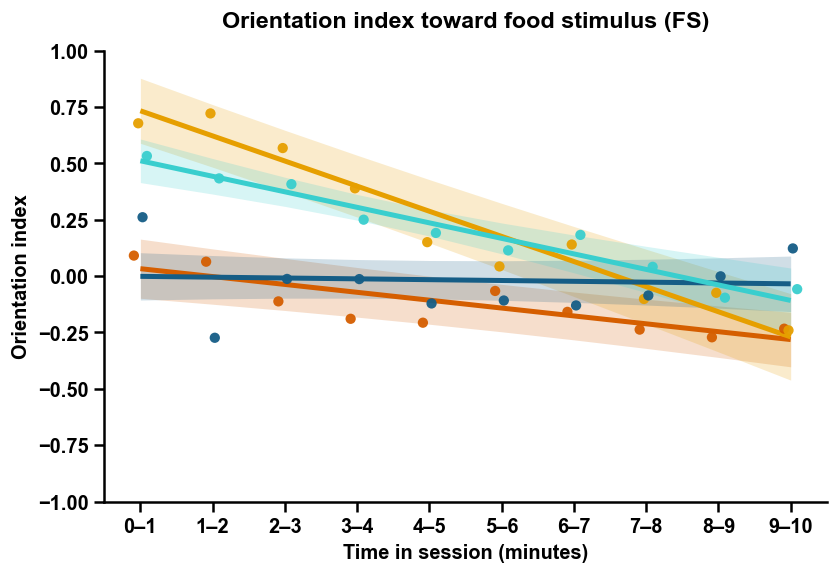

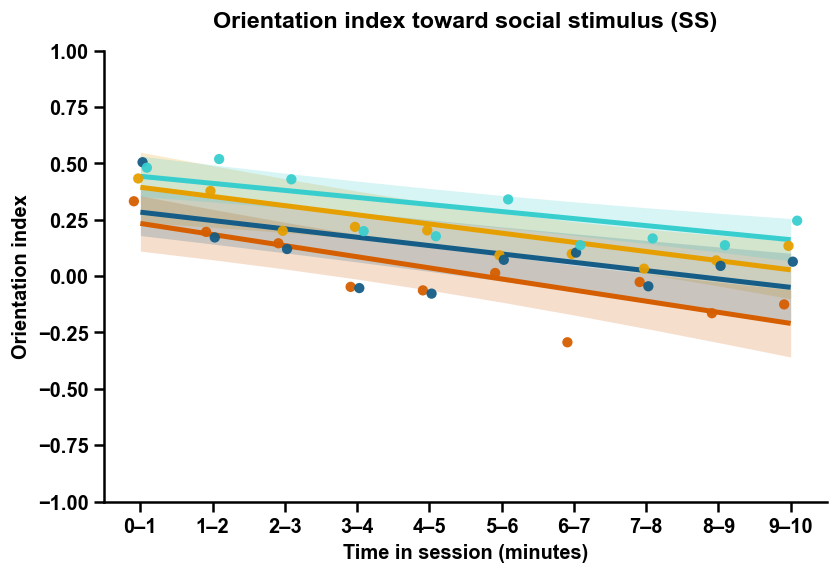

In [7]:
"""
Standalone, publication-matched orientation-index panels (SS and FS).

Run this AFTER the plotting cell (it reuses _order_groups,
_color_for, GROUP_COLORS, REFERENCE_GROUP, TREATMENT_COL, OUTCOMES, OUTCOME_LABELS
from that cell) and after `df = pd.read_csv(TIME_COURSE_CSV)`.

Style is matched to the "Bout duration in food stimulus zone (FS)" panel:
  Arial bold 12 pt (title 14 pt), 1.5 pt spines, 6 pt outward ticks,
  3 pt fitted lines (same width for every group), 6 pt dots dodged sideways,
  ribbons alpha 0.2, xlim (-0.5, 9.5), figure ~7.15 x 4.95 in, no top/right spines.
"""
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

# ---- style knobs (these reproduce the bout-duration panel) -------------------
PANEL_FIGSIZE   = (7.15, 4.95)     # inches; keep identical for K, L and M
PANEL_FONT      = 12               # tick labels, axis labels, legend
PANEL_TITLE     = 14
SPINE_LW        = 1.5
TICK_LEN        = 6
LINE_LW         = 3.0
DOT_SIZE        = 38               # scatter s (pt^2) ~ 6 pt diameter
RIBBON_ALPHA    = 0.20
DODGE           = {"GH AL": -0.09, "GH FD": -0.03, "SH AL": 0.03, "SH FD": 0.09}
GROUP_ORDER     = ["GH AL", "GH FD", "SH AL", "SH FD"]   # legend / draw order

PANEL_TITLES = {
    "mean_OI_SS": "Orientation index toward social stimulus (SS)",
    "mean_OI_FS": "Orientation index toward food stimulus (FS)",
}

PANEL_RC = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"],
    "font.weight": "bold",
    "font.size": PANEL_FONT,
    "axes.labelweight": "bold",
    "axes.labelsize": PANEL_FONT,
    "axes.titleweight": "bold",
    "axes.titlesize": PANEL_TITLE,
    "axes.titlepad": 14,
    "axes.linewidth": SPINE_LW,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.direction": "out", "ytick.direction": "out",
    "xtick.major.size": TICK_LEN, "ytick.major.size": TICK_LEN,
    "xtick.major.width": SPINE_LW, "ytick.major.width": SPINE_LW,
    "xtick.labelsize": PANEL_FONT, "ytick.labelsize": PANEL_FONT,
    "legend.fontsize": PANEL_FONT,
    "pdf.fonttype": 42, "ps.fonttype": 42,     # editable text in Illustrator
    "svg.fonttype": "none",
    "axes.unicode_minus": True,
    "savefig.dpi": 300,
}



def _fit_group_curve_v2(df, outcome, treatment_col, working_corr="ar"):
    """Same GEE as _fit_group_curve, but builds the prediction design matrix
    with patsy directly so it works across statsmodels versions."""
    import statsmodels.api as sm
    import statsmodels.formula.api as smf
    from patsy import dmatrix

    cov_map = {"ar": sm.cov_struct.Autoregressive,
               "exchangeable": sm.cov_struct.Exchangeable,
               "independence": sm.cov_struct.Independence}
    sub = df[["video", "time_bin", treatment_col, outcome]].dropna(subset=[outcome]).copy()
    cats = sorted(sub[treatment_col].astype(str).unique())
    sub[treatment_col] = pd.Categorical(sub[treatment_col].astype(str), categories=cats)

    res = smf.gee(f"{outcome} ~ time_bin * C({treatment_col})", groups="video",
                  data=sub, family=sm.families.Gaussian(),
                  cov_struct=cov_map[working_corr]()).fit(cov_type="robust")

    bins = np.sort(sub["time_bin"].unique())
    pred_df = pd.DataFrame([{"time_bin": b, treatment_col: g} for g in cats for b in bins])
    pred_df[treatment_col] = pd.Categorical(pred_df[treatment_col], categories=cats)

    X = dmatrix(f"time_bin * C({treatment_col})", pred_df, return_type="dataframe")
    X = X[list(res.params.index)]
    Xv, beta = X.values, res.params.values
    vcov = res.cov_params().values
    fit = Xv @ beta
    se = np.sqrt(np.einsum("ij,jk,ik->i", Xv, vcov, Xv))
    return pd.DataFrame({"group": pred_df[treatment_col].astype(str).values,
                         "time_bin": pred_df["time_bin"].values,
                         "fitted": fit, "ci_low": fit - 1.96 * se,
                         "ci_high": fit + 1.96 * se})


def plot_oi_panel(df, outcome, ylabel=True, title=True, legend=False,
                  out_name=None):
    """One standalone panel in the bout-duration style, WITH a y axis."""
    with mpl.rc_context(PANEL_RC):
        fig, ax = plt.subplots(figsize=PANEL_FIGSIZE)

        fitted = _fit_group_curve_v2(df, outcome, TREATMENT_COL)
        present = set(df[TREATMENT_COL].dropna().unique())
        groups = [g for g in GROUP_ORDER if g in present] + \
                 [g for g in _order_groups(present) if g not in GROUP_ORDER]

        for grp in groups:
            color = _color_for(grp)
            fg = fitted[fitted["group"] == grp].sort_values("time_bin")
            if fg.empty:
                continue
            x = fg["time_bin"].to_numpy() * (BIN_SECONDS / 60.0)

            ax.fill_between(x, fg["ci_low"], fg["ci_high"], color=color,
                            alpha=RIBBON_ALPHA, lw=0, zorder=2)
            ax.plot(x, fg["fitted"], color=color, lw=LINE_LW, label=grp,
                    solid_capstyle="butt", zorder=3)

            raw = (df[df[TREATMENT_COL] == grp]
                   .groupby("time_bin")[outcome].mean().reset_index())
            xr = raw["time_bin"] * (BIN_SECONDS / 60.0) + DODGE.get(grp, 0.0)
            ax.scatter(xr, raw[outcome], s=DOT_SIZE, color=color, alpha=0.95,
                       edgecolors="none", zorder=4, clip_on=False)

        # ---- axes: same construction as the bout-duration panel -------------
        ax.set_xlim(-0.5, X_MAX_MINUTES - 0.5)
        ax.set_ylim(Y_MIN_OI, Y_MAX_OI)
        ticks = np.arange(0, X_MAX_MINUTES)
        ax.xaxis.set_major_locator(FixedLocator(ticks))
        ax.set_xticklabels([f"{t}\u2013{t + 1}" for t in ticks])
        ax.set_yticks(np.arange(Y_MIN_OI, Y_MAX_OI + 1e-9, 0.25))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.2f}".replace("-", "\u2212")))
        for lab in ax.get_xticklabels() + ax.get_yticklabels():
            lab.set_fontweight("bold")

        ax.set_xlabel("Time in session (minutes)")
        if ylabel:
            ax.set_ylabel("Orientation index")
        if title:
            ax.set_title(PANEL_TITLES[outcome])
        if legend:
            ax.legend(frameon=False, loc="upper right", handlelength=2.6,
                      labelspacing=0.5)

        fig.tight_layout()
        if out_name:
            for ext in ("png", "pdf"):
                fig.savefig(f"{out_name}.{ext}", bbox_inches="tight")
            print(f"  saved {out_name}.png / .pdf")
        return fig

# Load the binned data frame before running the plotting function
df = pd.read_csv("advanced_analysis_plots/time_course_orientation.csv") 

# ---- make both panels (FS is the one that goes in panel M) -------------------
fig_fs = plot_oi_panel(df, "mean_OI_FS", legend=False, out_name="figM_orientation_FS_new")
fig_ss = plot_oi_panel(df, "mean_OI_SS", legend=False, out_name="figM_orientation_SS")
plt.show()


In [ ]:
import pandas as pd
trends = pd.read_csv("time_course_orientation_treatment_trends.csv")
print("Shape:", trends.shape)
print("\nColumns:", list(trends.columns))
print("\nterm_type values:\n", trends["term_type"].value_counts(dropna=False))
print("\noutcome values:\n", trends["outcome"].value_counts(dropna=False))
print("\nmodel values:\n", trends["model"].value_counts(dropna=False))

Shape: (0, 18)

Columns: ['outcome', 'model', 'term_type', 'term', 'beta', 'se', 'ci_low', 'ci_high', 'stat_name', 'stat_value', 'p_value', 'p_value_holm', 'n_clusters', 'n_obs', 'global_wald_stat', 'global_wald_df', 'global_wald_p', 'reference_group']

term_type values:
 Series([], Name: count, dtype: int64)

outcome values:
 Series([], Name: count, dtype: int64)

model values:
 Series([], Name: count, dtype: int64)


In [ ]:
import pandas as pd

# ---- Speed trends ----
sp = pd.read_csv("advanced_analysis_plots/time_course_speed_treatment_trends.csv")
print(sp[["outcome","model","term_type","term","beta","se","ci_low","ci_high",
          "p_value","p_value_holm","global_wald_stat","global_wald_p"]]
      .to_string(index=False))

# ---- Orientation trends (whichever version has rows) ----
import os
for f in ["time_course_orientation_treatment_trends.csv"]:
    if os.path.exists(f):
        ori = pd.read_csv(f)
        print("\n", f, "shape:", ori.shape)
        if len(ori):
            print(ori[["outcome","model","term_type","term","beta","se",
                       "ci_low","ci_high","p_value","p_value_holm",
                       "global_wald_p"]].to_string(index=False))

# ---- Per-video fit quality (both outcomes) ----
for f in ["advanced_analysis_plots/time_course_speed_fit_quality.csv",
          "time_course_orientation_fit_quality.csv"]:
    if os.path.exists(f):
        fq = pd.read_csv(f)
        print("\n", f)
        for outcome, g in fq.groupby("outcome"):
            r2 = g["r_squared"].dropna()
            print(f"  {outcome:22s} n={len(g)}  R² med={r2.median():.3f}  "
                  f"p<.05: {(g['p_value']<0.05).sum()}/{len(g)}  "
                  f"median slope={g['slope'].median():+.4f}")

# ---- Descriptive means per group (for the opening sentence) ----
tc = pd.read_csv("advanced_analysis_plots/time_course_speed.csv")
print("\nGroup means of approach_speed_SS / _FS across all bins:")
print(tc.groupby("Treatment")[["approach_speed_SS","approach_speed_FS"]].mean())

          outcome            model    term_type                           term      beta       se    ci_low  ci_high  p_value  p_value_holm  global_wald_stat  global_wald_p
approach_speed_SS GEE (ar, robust)  interaction time_bin:C(Treatment)[T.GH FD]  0.075798 0.247443 -0.409181 0.560777 0.760908      1.000000          3.518692       0.318346
approach_speed_SS GEE (ar, robust)  interaction time_bin:C(Treatment)[T.SH AL]  0.027463 0.198908 -0.362390 0.417317 0.890861      1.000000          3.518692       0.318346
approach_speed_SS GEE (ar, robust)  interaction time_bin:C(Treatment)[T.SH FD] -0.371371 0.217473 -0.797610 0.054869 0.095262      0.285786          3.518692       0.318346
approach_speed_SS  MixedLM (RI+RS)  interaction time_bin:C(Treatment)[T.GH FD]  0.007351 0.317975 -0.615867 0.630570 0.981555           NaN               NaN            NaN
approach_speed_SS  MixedLM (RI+RS)  interaction time_bin:C(Treatment)[T.SH AL] -0.029538 0.288517 -0.595020 0.535945 0.918457          